# IT3091 — Telco Customer Churn Prediction
## Logistic Regression Model Development
**Member:** IT24101780  
**Notebook:** `08_logistic_regression.ipynb`

---

### Experiment Plan
| Step | Configuration | Purpose |
|------|---------------|---------|
| 8.1 | Baseline features · No balancing | Reference starting point |
| 8.2 | Baseline features · class_weight="balanced" | Built-in imbalance handling |
| 8.3 | Baseline features · Random oversampling | Explicit resampling |
| 8.4 | Engineered features · No balancing | Feature engineering impact |
| 8.5 | Engineered features · class_weight="balanced" | Best combined strategy |
| 8.6 | Engineered features · Random oversampling | Feature + resampling |
| 8.7 | Summary comparison table | Select best configuration |
| 8.8 | Final test set evaluation | Held-out test evaluation |
| 8.9 | Save results and model | Persist outputs |

##### Cell 1 — Import shared functions and prepare data

In [1]:

# ==========================================================
# IT3091 - Telco Customer Churn
# Logistic Regression Model Development
# Member: IT24101780
# Step 8.1 - Setup and Data Preparation
# ==========================================================

import sys
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
import joblib

from src.data_preparation import (
    load_and_clean_data,
    separate_features_target
)
from src.validation import create_train_test_split
from src.imbalance import build_model_pipeline
from src.evaluation import evaluate_cv

# Load cleaned dataset
df = load_and_clean_data(project_root)

# Separate predictors and target
X, y = separate_features_target(df)

# Reuse shared 80/20 stratified split
X_train, X_test, y_train, y_test = create_train_test_split(X, y)

print("Logistic Regression imports successful!")
print("Training records:", len(X_train))
print("Testing records: ", len(X_test))
print("Training features:", X_train.shape[1])
print("Churn rate (train):", round(y_train.mean(), 4))


Logistic Regression imports successful!
Training records: 5634
Testing records:  1409
Training features: 19
Churn rate (train): 0.2654


##### Cell 2 — Step 8.1: Baseline features, no class balancing

In [2]:

# ==========================================================
# Step 8.1 — Baseline LR · No balancing
# scale_numeric=True (required for LR convergence)
# add_engineered_features=False
# imbalance_strategy="none"
# ==========================================================

lr_baseline_none = build_model_pipeline(
    model=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=False,
    imbalance_strategy="none"
)

print("Pipeline steps:", list(lr_baseline_none.named_steps.keys()))

results_81 = evaluate_cv(lr_baseline_none, X_train, y_train)
results_81.insert(0, "Configuration", "Baseline · No balancing")
display(results_81)


Pipeline steps: ['features', 'preprocessor', 'model']


,Configuration,Metric,Mean,Std
0,Baseline · No balancing,F1,0.5931,0.0298
1,Baseline · No balancing,Recall,0.5438,0.0409
2,Baseline · No balancing,Precision,0.6538,0.0270
3,Baseline · No balancing,ROC_AUC,0.8462,0.0126
4,Baseline · No balancing,Accuracy,0.8025,0.0120


##### Cell 3 — Step 8.2: Baseline features, class_weight="balanced"

In [3]:

# ==========================================================
# Step 8.2 — Baseline LR · class_weight="balanced"
# The class_weight parameter is set directly on the
# LogisticRegression estimator — no resampling step added.
# ==========================================================

lr_baseline_balanced = build_model_pipeline(
    model=LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=False,
    imbalance_strategy="none"
)

results_82 = evaluate_cv(lr_baseline_balanced, X_train, y_train)
results_82.insert(0, "Configuration", "Baseline · class_weight=balanced")
display(results_82)


,Configuration,Metric,Mean,Std
0,Baseline · class_weight=balanced,F1,0.6281,0.0234
1,Baseline · class_weight=balanced,Recall,0.8013,0.0379
2,Baseline · class_weight=balanced,Precision,0.5167,0.0190
3,Baseline · class_weight=balanced,ROC_AUC,0.8460,0.0124
4,Baseline · class_weight=balanced,Accuracy,0.7483,0.0154


##### Cell 4 — Step 8.3: Baseline features, random oversampling

In [4]:

# ==========================================================
# Step 8.3 — Baseline LR · Random oversampling
# RandomOverSampler is applied inside each CV fold
# via build_model_pipeline (training data only).
# ==========================================================

lr_baseline_ros = build_model_pipeline(
    model=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=False,
    imbalance_strategy="random_oversampling"
)

print("Pipeline steps:", list(lr_baseline_ros.named_steps.keys()))

results_83 = evaluate_cv(lr_baseline_ros, X_train, y_train)
results_83.insert(0, "Configuration", "Baseline · Random oversampling")
display(results_83)


Pipeline steps: ['features', 'preprocessor', 'sampler', 'model']


,Configuration,Metric,Mean,Std
0,Baseline · Random oversampling,F1,0.6278,0.0196
1,Baseline · Random oversampling,Recall,0.8013,0.0393
2,Baseline · Random oversampling,Precision,0.5163,0.0135
3,Baseline · Random oversampling,ROC_AUC,0.8457,0.0127
4,Baseline · Random oversampling,Accuracy,0.7481,0.0109


##### Cell 5 — Step 8.4: Engineered features, no class balancing

In [5]:

# ==========================================================
# Step 8.4 — Engineered features · No balancing
# add_engineered_features=True adds TenureGroup and
# ServiceCount. Preprocessor expands to 50 columns.
# ==========================================================

lr_eng_none = build_model_pipeline(
    model=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=True,
    imbalance_strategy="none"
)

results_84 = evaluate_cv(lr_eng_none, X_train, y_train)
results_84.insert(0, "Configuration", "Engineered · No balancing")
display(results_84)


,Configuration,Metric,Mean,Std
0,Engineered · No balancing,F1,0.5936,0.0243
1,Engineered · No balancing,Recall,0.5358,0.0374
2,Engineered · No balancing,Precision,0.6673,0.0182
3,Engineered · No balancing,ROC_AUC,0.8465,0.0116
4,Engineered · No balancing,Accuracy,0.8058,0.0078


##### Cell 6 — Step 8.5: Engineered features, class_weight="balanced"

In [6]:

# ==========================================================
# Step 8.5 — Engineered features · class_weight="balanced"
# ==========================================================

lr_eng_balanced = build_model_pipeline(
    model=LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=True,
    imbalance_strategy="none"
)

results_85 = evaluate_cv(lr_eng_balanced, X_train, y_train)
results_85.insert(0, "Configuration", "Engineered · class_weight=balanced")
display(results_85)


,Configuration,Metric,Mean,Std
0,Engineered · class_weight=balanced,F1,0.6272,0.0206
1,Engineered · class_weight=balanced,Recall,0.7967,0.0379
2,Engineered · class_weight=balanced,Precision,0.5175,0.0162
3,Engineered · class_weight=balanced,ROC_AUC,0.8463,0.0114
4,Engineered · class_weight=balanced,Accuracy,0.7488,0.0129


##### Cell 7 — Step 8.6: Engineered features, random oversampling

In [7]:

# ==========================================================
# Step 8.6 — Engineered features · Random oversampling
# ==========================================================

lr_eng_ros = build_model_pipeline(
    model=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    scale_numeric=True,
    add_engineered_features=True,
    imbalance_strategy="random_oversampling"
)

results_86 = evaluate_cv(lr_eng_ros, X_train, y_train)
results_86.insert(0, "Configuration", "Engineered · Random oversampling")
display(results_86)


,Configuration,Metric,Mean,Std
0,Engineered · Random oversampling,F1,0.6266,0.0175
1,Engineered · Random oversampling,Recall,0.7973,0.0343
2,Engineered · Random oversampling,Precision,0.5163,0.0139
3,Engineered · Random oversampling,ROC_AUC,0.8462,0.0119
4,Engineered · Random oversampling,Accuracy,0.7480,0.0109


##### Cell 8 — Step 8.7: Summary comparison of all configurations

In [8]:

# ==========================================================
# Step 8.7 — Summary comparison table
# Pivot so each row = one configuration, columns = metrics
# Primary metric for selection: F1
# ==========================================================

all_results = pd.concat(
    [results_81, results_82, results_83,
     results_84, results_85, results_86],
    ignore_index=True
)

# Pivot: one row per configuration, columns = Mean_<Metric>
summary = all_results.pivot_table(
    index="Configuration",
    columns="Metric",
    values="Mean"
).reset_index()

# Reorder columns for readability
metric_cols = [c for c in ["F1", "Recall", "Precision", "ROC_AUC", "Accuracy"]
               if c in summary.columns]
summary = summary[["Configuration"] + metric_cols]

# Mark best F1 configuration
best_idx = summary["F1"].idxmax()
print(f"Best configuration (F1): {summary.loc[best_idx, 'Configuration']}")
print(f"Best F1 mean:            {summary.loc[best_idx, 'F1']:.4f}")
print()
display(summary.sort_values("F1", ascending=False))

# Save to results/tables/
tables_dir = project_root / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
summary.to_csv(tables_dir / "logistic_regression_cv.csv", index=False)
print("CV results saved to results/tables/logistic_regression_cv.csv")


Best configuration (F1): Baseline · class_weight=balanced
Best F1 mean:            0.6281



Metric,Configuration,F1,Recall,Precision,ROC_AUC,Accuracy
2,Baseline · class_weight=balanced,0.6281,0.8013,0.5167,0.8460,0.7483
1,Baseline · Random oversampling,0.6278,0.8013,0.5163,0.8457,0.7481
5,Engineered · class_weight=balanced,0.6272,0.7967,0.5175,0.8463,0.7488
4,Engineered · Random oversampling,0.6266,0.7973,0.5163,0.8462,0.7480
3,Engineered · No balancing,0.5936,0.5358,0.6673,0.8465,0.8058
0,Baseline · No balancing,0.5931,0.5438,0.6538,0.8462,0.8025


CV results saved to results/tables/logistic_regression_cv.csv


##### Cell 9 — Step 8.7b: Bar chart — F1 comparison across configurations

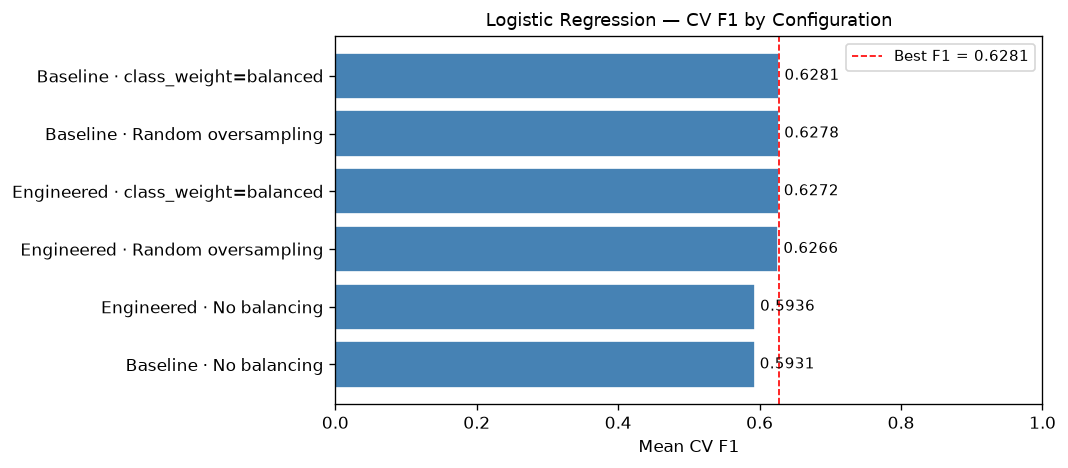

Figure saved to results/figures/logistic_regression/lr_cv_f1_comparison.png


In [9]:

# ==========================================================
# Step 8.7b — Bar chart: F1 by configuration
# ==========================================================

figures_dir = project_root / "results" / "figures" / "logistic_regression"
figures_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4))

configs = summary.sort_values("F1", ascending=True)["Configuration"]
f1_vals = summary.sort_values("F1", ascending=True)["F1"]

bars = ax.barh(configs, f1_vals, color="steelblue", edgecolor="white")
ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
ax.set_xlabel("Mean CV F1")
ax.set_title("Logistic Regression — CV F1 by Configuration", fontsize=11)
ax.set_xlim(0, 1.0)
ax.axvline(x=f1_vals.max(), color="red", linestyle="--", linewidth=1,
           label=f"Best F1 = {f1_vals.max():.4f}")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(figures_dir / "lr_cv_f1_comparison.png", bbox_inches="tight")
plt.show()
print("Figure saved to results/figures/logistic_regression/lr_cv_f1_comparison.png")


##### Cell 10 — Step 8.8: Retrain best configuration and evaluate on held-out test set

In [10]:

# ==========================================================
# Step 8.8 — Final test set evaluation
#
# Select the configuration with the highest CV F1.
# Retrain on the full training set and evaluate on
# the untouched held-out test set (X_test, y_test).
#
# IMPORTANT: The test set is accessed only once here.
# ==========================================================

best_config_name = summary.loc[summary["F1"].idxmax(), "Configuration"]
print(f"Best CV configuration: {best_config_name}")
print("Retraining on full training set ...")

# Map configuration name back to the pipeline object
config_map = {
    "Baseline · No balancing":             lr_baseline_none,
    "Baseline · class_weight=balanced":    lr_baseline_balanced,
    "Baseline · Random oversampling":      lr_baseline_ros,
    "Engineered · No balancing":           lr_eng_none,
    "Engineered · class_weight=balanced":  lr_eng_balanced,
    "Engineered · Random oversampling":    lr_eng_ros,
}

best_pipeline = config_map[best_config_name]
best_pipeline.fit(X_train, y_train)

y_pred  = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

print()
print("=" * 55)
print("HELD-OUT TEST SET EVALUATION — Logistic Regression")
print("=" * 55)
print(classification_report(y_test, y_pred,
                             target_names=["No Churn", "Churn"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")


Best CV configuration: Baseline · class_weight=balanced
Retraining on full training set ...

HELD-OUT TEST SET EVALUATION — Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8416


##### Cell 11 — Confusion matrix and ROC curve for best model

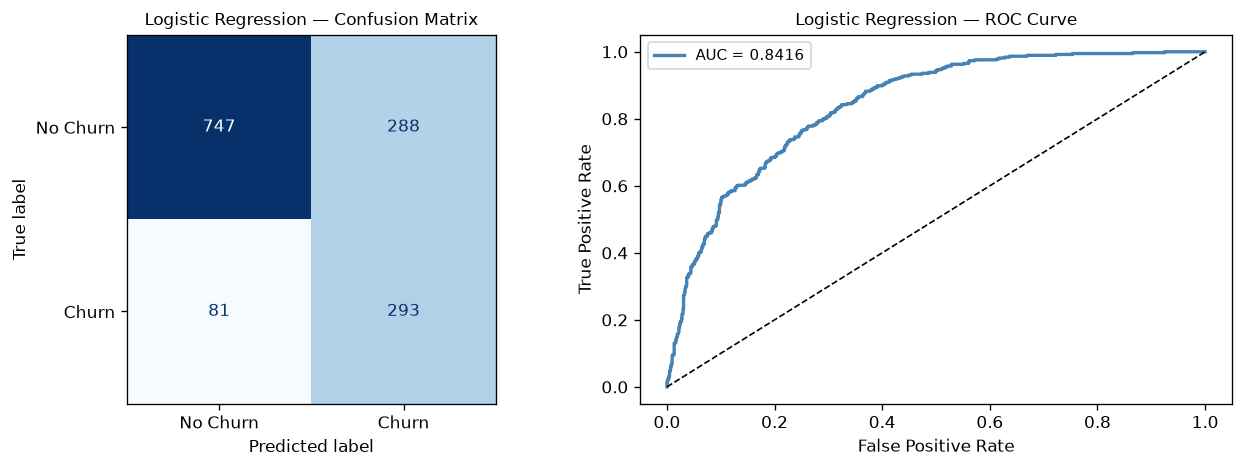

Figure saved to results/figures/logistic_regression/lr_test_cm_roc.png


In [11]:

# ==========================================================
# Confusion matrix and ROC curve — test set
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)
disp.plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Logistic Regression — Confusion Matrix", fontsize=10)

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)
axes[1].plot(fpr, tpr, color="steelblue", lw=2,
             label=f"AUC = {auc_score:.4f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Logistic Regression — ROC Curve", fontsize=10)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / "lr_test_cm_roc.png", bbox_inches="tight")
plt.show()
print("Figure saved to results/figures/logistic_regression/lr_test_cm_roc.png")


##### Cell 12 — Step 8.9: Save final test metrics and model

In [12]:

# ==========================================================
# Step 8.9 — Save results and model
# ==========================================================

from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score

test_metrics = pd.DataFrame([
    {"Metric": "F1",        "Value": round(f1_score(y_test, y_pred), 4)},
    {"Metric": "Recall",    "Value": round(recall_score(y_test, y_pred), 4)},
    {"Metric": "Precision", "Value": round(precision_score(y_test, y_pred), 4)},
    {"Metric": "ROC_AUC",   "Value": round(roc_auc_score(y_test, y_proba), 4)},
    {"Metric": "Accuracy",  "Value": round(accuracy_score(y_test, y_pred), 4)},
])

test_metrics.insert(0, "Model", "Logistic Regression")
test_metrics.insert(1, "Configuration", best_config_name)

display(test_metrics)

# Save test metrics
test_metrics.to_csv(
    tables_dir / "logistic_regression_test_metrics.csv",
    index=False
)
print("Test metrics saved to results/tables/logistic_regression_test_metrics.csv")

# Save model
models_dir = project_root / "results" / "models"
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(best_pipeline, models_dir / "logistic_regression.joblib")
print("Model saved to results/models/logistic_regression.joblib")


,Model,Configuration,Metric,Value
0,Logistic Regression,Baseline · class_weight=balanced,F1,0.6136
1,Logistic Regression,Baseline · class_weight=balanced,Recall,0.7834
2,Logistic Regression,Baseline · class_weight=balanced,Precision,0.5043
3,Logistic Regression,Baseline · class_weight=balanced,ROC_AUC,0.8416
4,Logistic Regression,Baseline · class_weight=balanced,Accuracy,0.7381


Test metrics saved to results/tables/logistic_regression_test_metrics.csv
Model saved to results/models/logistic_regression.joblib
